# O que os canais lo-fi / ambiente bem-sucedidos têm em comum?

Análise de canais de lo-fi, ambiente, study e sleep music coletados via YouTube Data API v3
(`src/collect.py`) e tratados em `src/clean.py`.

**Sucesso** = canal no top 25% em **mediana de views por vídeo** (últimos até 50 vídeos).
Usamos a mediana para que um único hit viral não defina o canal.

As comparações são feitas **por canal** (cada canal pesa igual), não por vídeo.

In [1]:
from pathlib import Path
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Paleta: azul = bem-sucedidos, laranja = demais; tinta de texto neutra
COLOR_SUCCESS = "#2a78d6"
COLOR_OTHER = "#eb6834"
GROUP_COLORS = {True: COLOR_SUCCESS, False: COLOR_OTHER}
GROUP_LABELS = {True: "Bem-sucedidos (top 25%)", False: "Demais"}
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "text.color": INK,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
})


def save(fig, name):
    """Salva a figura em figures/ para uso no README."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## 1. Dados

In [2]:
channels = pd.read_csv(DATA_DIR / "channels.csv")
videos = pd.read_csv(DATA_DIR / "videos.csv", parse_dates=["published_at"])

threshold = channels.loc[channels["success"], "median_views"].min()
print(f"{len(channels)} canais, {len(videos):,} vídeos")
print(f"{channels['success'].sum()} canais bem-sucedidos (mediana >= {threshold:,.0f} views/vídeo)")

367 canais, 17,354 vídeos
92 canais bem-sucedidos (mediana >= 15,587 views/vídeo)


Cada canal tem até 50 vídeos recentes. Para comparar padrões de título sem dar mais peso a
canais com mais vídeos, transformamos as features de vídeo em **% dos vídeos do canal**.

In [3]:
TITLE_FLAGS = {
    "emoji_pct": videos["emoji_count"] > 0,
    "pipe_pct": videos["has_pipe"],
    "year_pct": videos["has_year"],
    "live_title_pct": videos["has_live"],
    "beats_to_pct": videos["has_beats_to"],
    "24_7_pct": videos["has_24_7"],
}
title_features = (
    videos.assign(**{k: v.astype(float) * 100 for k, v in TITLE_FLAGS.items()})
    .groupby("channel_id")
    .agg(mean_title_length=("title_length", "mean"), **{k: (k, "mean") for k in TITLE_FLAGS})
    .reset_index()
)
channels = channels.merge(title_features, on="channel_id", how="left")
channels[["title", "subscribers", "median_views", "success"]].sort_values("median_views", ascending=False).head(10)

,title,subscribers,median_views,success
267,kno Piano Music,900000,4629874.0,True
263,Rousseau,5610000,4284571.5,True
331,Emilio Piano,9160000,3612098.0,True
278,Flavour Trip,874000,2080801.5,True
191,space station,45900,1194668.5,True
139,Calmed By Nature,778000,722032.5,True
341,Shine Music,806000,575878.5,True
350,Chill Out & Lounge Music,93000,552572.5,True
168,Abao Vision,367000,485454.5,True
170,Settle,138000,430486.0,True


## 2. Comparação entre grupos

Para cada feature: mediana em cada grupo e um **teste de permutação** da diferença de medianas
(10.000 embaralhamentos dos rótulos). O p-valor diz com que frequência uma diferença tão grande
surgiria se o rótulo de sucesso fosse aleatório.

In [4]:
FEATURES = {
    "subscribers": "Inscritos",
    "age_years": "Idade do canal (anos)",
    "video_count": "Nº total de vídeos",
    "uploads_per_week": "Uploads por semana",
    "mean_duration_min": "Duração média (min)",
    "live_pct": "% de lives/estreias",
    "mean_engagement": "Engajamento médio",
    "mean_title_length": "Tamanho médio do título",
    "emoji_pct": "% títulos com emoji",
    "pipe_pct": "% títulos com '|'",
    "year_pct": "% títulos com ano",
}


def permutation_pvalue(a, b, n_perm=10_000, seed=42):
    """p-valor bicaudal da diferença de medianas via permutação dos rótulos."""
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a), np.asarray(b)
    observed = abs(np.median(a) - np.median(b))
    pooled = np.concatenate([a, b])
    hits = 0
    for _ in range(n_perm):
        rng.shuffle(pooled)
        hits += abs(np.median(pooled[: len(a)]) - np.median(pooled[len(a):])) >= observed
    return (hits + 1) / (n_perm + 1)


def compare_groups(df, features):
    rows = []
    for col, label in features.items():
        win = df.loc[df["success"], col].dropna()
        rest = df.loc[~df["success"], col].dropna()
        rows.append({
            "feature": label,
            "mediana_sucesso": win.median(),
            "mediana_demais": rest.median(),
            "p_valor": permutation_pvalue(win, rest),
        })
    return pd.DataFrame(rows).set_index("feature")


comparison = compare_groups(channels, FEATURES)
comparison.round(4)

,mediana_sucesso,mediana_demais,p_valor
feature,,,
Inscritos,509500.0000,57700.0000,0.0001
Idade do canal (anos),7.7372,5.4867,0.0089
Nº total de vídeos,203.5000,218.0000,0.6843
Uploads por semana,0.5260,2.1085,0.0005
Duração média (min),102.1508,134.3183,0.1531
% de lives/estreias,1.0000,5.7143,0.0586
Engajamento médio,0.0159,0.0197,0.0489
Tamanho médio do título,66.1900,76.4324,0.0012
% títulos com emoji,8.0000,16.0000,0.1862


### Boxplots por feature
Escala log nas features muito assimétricas. Caixa = quartis; linha = mediana.

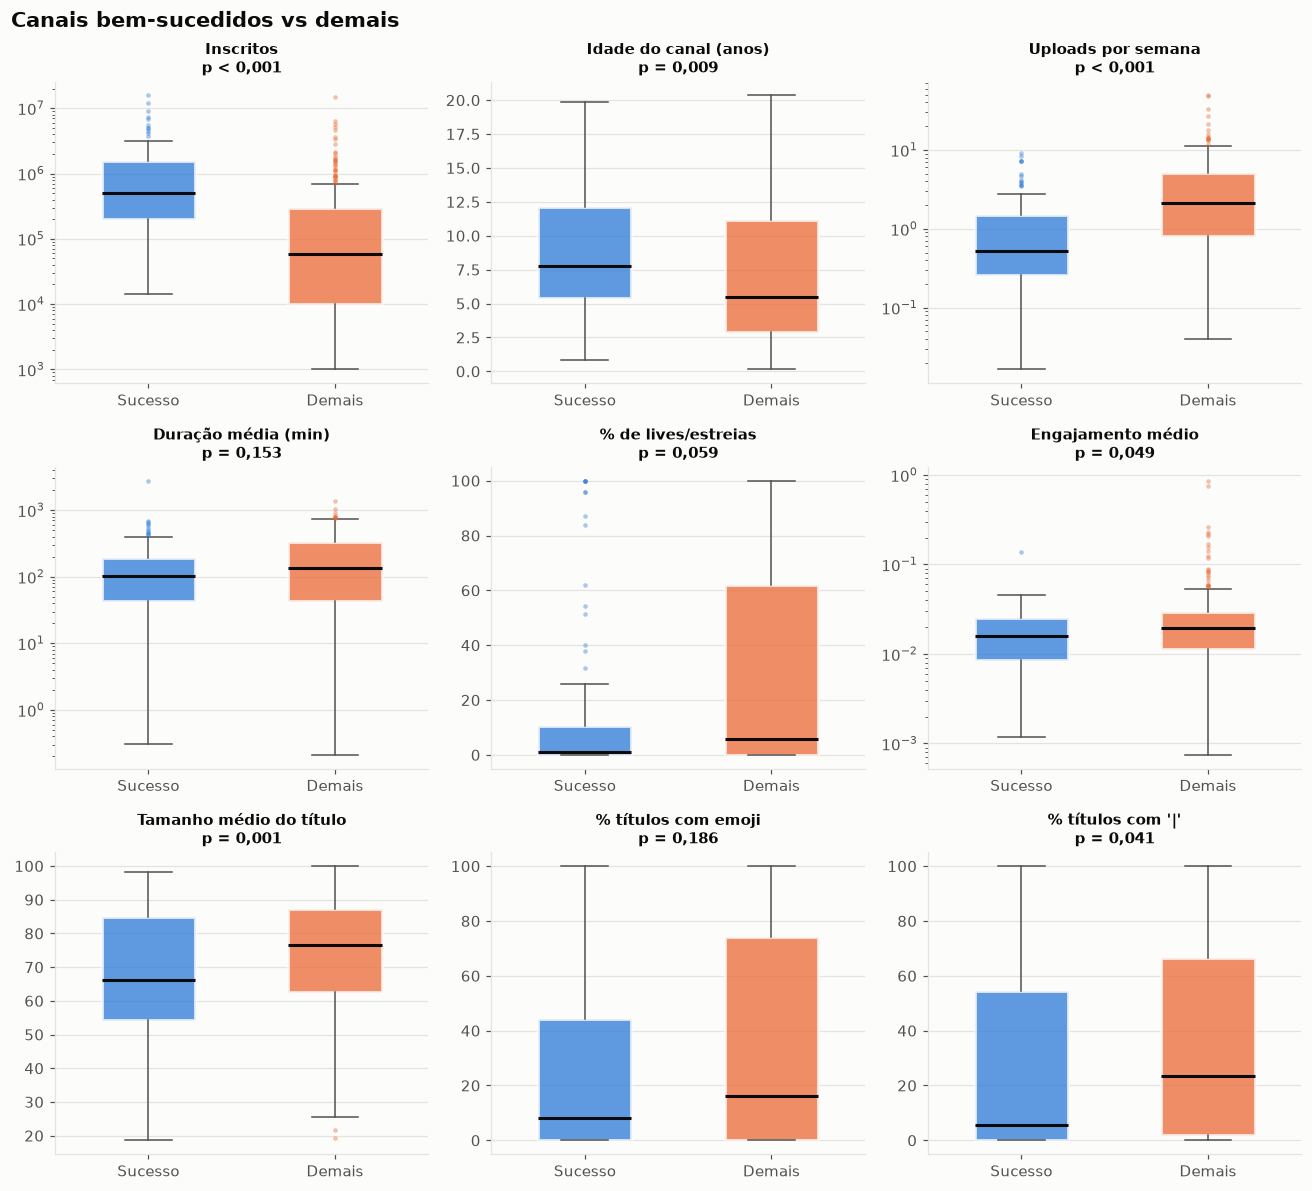

In [5]:
BOX_FEATURES = [
    ("subscribers", True), ("age_years", False), ("uploads_per_week", True),
    ("mean_duration_min", True), ("live_pct", False), ("mean_engagement", True),
    ("mean_title_length", False), ("emoji_pct", False), ("pipe_pct", False),
]


def boxplot_by_group(ax, df, col, log_scale):
    order = [True, False]
    data = [df.loc[df["success"] == g, col].dropna() for g in order]
    if log_scale:
        data = [d[d > 0] for d in data]
    parts = ax.boxplot(
        data, tick_labels=["Sucesso", "Demais"], widths=0.5, patch_artist=True,
        medianprops={"color": INK, "linewidth": 2},
        flierprops={"marker": "o", "markersize": 3, "alpha": 0.4, "markeredgewidth": 0},
        whiskerprops={"color": INK_MUTED}, capprops={"color": INK_MUTED},
    )
    for box, flier, g in zip(parts["boxes"], parts["fliers"], order):
        box.set(facecolor=GROUP_COLORS[g], alpha=0.75, edgecolor=SURFACE, linewidth=2)
        flier.set_markerfacecolor(GROUP_COLORS[g])
    if log_scale:
        ax.set_yscale("log")
    p = comparison.loc[FEATURES[col], "p_valor"]
    p_text = "p < 0,001" if p < 0.001 else f"p = {p:.3f}".replace(".", ",")
    ax.set_title(f"{FEATURES[col]}\n{p_text}", fontsize=10)
    ax.grid(axis="x", visible=False)


fig, axes = plt.subplots(3, 3, figsize=(12, 11))
for ax, (col, log_scale) in zip(axes.flat, BOX_FEATURES):
    boxplot_by_group(ax, channels, col, log_scale)
fig.suptitle("Canais bem-sucedidos vs demais", fontsize=14, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
save(fig, "boxplots_features")

## 3. Formato dos vídeos: duração e lives

success,False,True
< 10 min,26.0,25.2
10–30 min,4.5,5.9
30–60 min,4.1,9.2
1–3 h,25.6,28.9
3–10 h,22.4,20.4
> 10 h,17.4,10.3


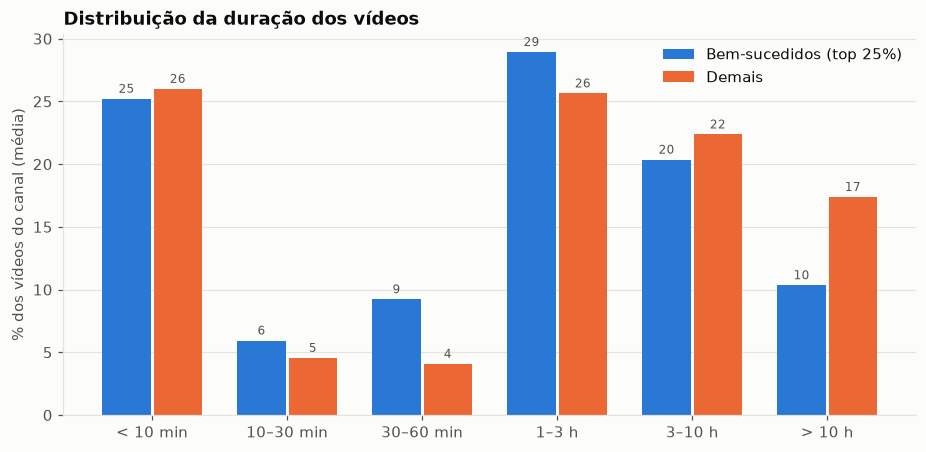

In [6]:
DURATION_BINS = [0, 10, 30, 60, 180, 600, np.inf]
DURATION_LABELS = ["< 10 min", "10–30 min", "30–60 min", "1–3 h", "3–10 h", "> 10 h"]
videos["duration_bucket"] = pd.cut(videos["duration_min"], DURATION_BINS, labels=DURATION_LABELS, right=False)

# % de vídeos em cada faixa, calculado por canal e depois a média entre canais
bucket_share = (
    pd.crosstab(videos["channel_id"], videos["duration_bucket"], normalize="index")
    .mul(100)
    .join(channels.set_index("channel_id")["success"])
    .groupby("success").mean()
    .T
)


def grouped_bars(ax, table, ylabel):
    """Barras lado a lado por grupo, com rótulo de valor no topo."""
    x = np.arange(len(table))
    width = 0.38
    for i, g in enumerate([True, False]):
        bars = ax.bar(x + (i - 0.5) * width, table[g], width - 0.02,
                      color=GROUP_COLORS[g], label=GROUP_LABELS[g])
        ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=8, color=INK_MUTED)
    ax.set_xticks(x, table.index)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False)


fig, ax = plt.subplots(figsize=(10, 4.5))
grouped_bars(ax, bucket_share, "% dos vídeos do canal (média)")
ax.set_title("Distribuição da duração dos vídeos", loc="left")
save(fig, "duracao_videos")
bucket_share.round(1)

> **Atenção:** `is_live` vem da presença de `liveStreamingDetails` na API, que também existe em
> **estreias (Premieres)**. Por isso "% de lives" mede lives + estreias.

## 4. Quando publicar: dia da semana e hora (UTC)

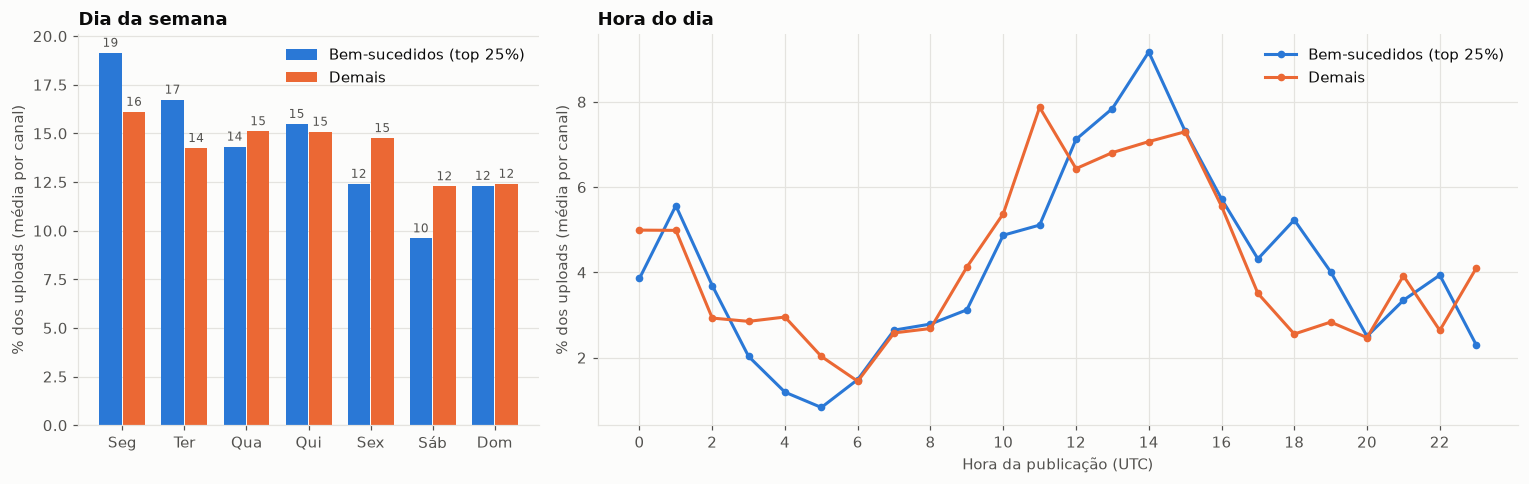

In [7]:
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
WEEKDAYS_PT = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]


def share_by_group(column, order):
    """% dos vídeos em cada categoria, média entre canais de cada grupo."""
    return (
        pd.crosstab(videos["channel_id"], videos[column], normalize="index")
        .reindex(columns=order, fill_value=0)
        .mul(100)
        .join(channels.set_index("channel_id")["success"])
        .groupby("success").mean()
        .T
    )


weekday_share = share_by_group("weekday", WEEKDAYS).set_axis(WEEKDAYS_PT)
hour_share = share_by_group("hour_utc", list(range(24)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
grouped_bars(ax1, weekday_share, "% dos uploads (média por canal)")
ax1.set_title("Dia da semana", loc="left")
for g in [True, False]:
    ax2.plot(hour_share.index, hour_share[g], color=GROUP_COLORS[g], linewidth=2,
             marker="o", markersize=4, label=GROUP_LABELS[g])
ax2.set_xticks(range(0, 24, 2))
ax2.set_xlabel("Hora da publicação (UTC)")
ax2.set_ylabel("% dos uploads (média por canal)")
ax2.set_title("Hora do dia", loc="left")
ax2.legend(frameon=False)
fig.tight_layout()
save(fig, "quando_publicar")

## 5. Correlações

Correlação de **Spearman** (baseada em ranking, robusta a outliers e a relações não lineares)
entre as features de canal e a mediana de views.

Uploads por semana        -0.36
Engajamento médio         -0.27
% de lives/estreias       -0.21
% títulos com '|'         -0.20
% títulos com emoji       -0.16
Tamanho médio do título   -0.15
Duração média (min)       -0.08
% títulos com ano         -0.03
Nº total de vídeos         0.11
Idade do canal (anos)      0.33
Inscritos                  0.63
Name: Mediana de views, dtype: float64

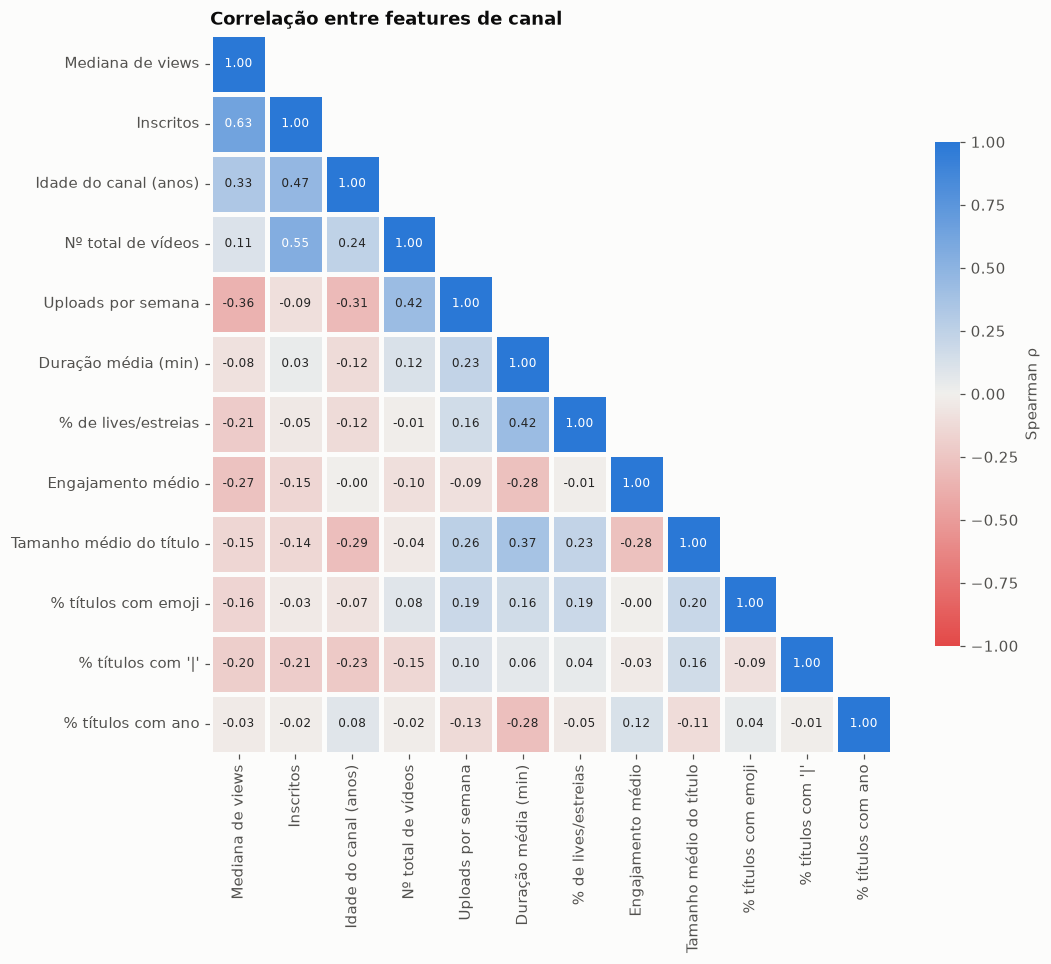

In [8]:
corr_cols = ["median_views"] + list(FEATURES)
corr = channels[corr_cols].corr(method="spearman").rename(index=FEATURES, columns=FEATURES)
corr = corr.rename(index={"median_views": "Mediana de views"}, columns={"median_views": "Mediana de views"})

# Divergente: vermelho (negativo) -> cinza neutro (zero) -> azul (positivo)
diverging = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, mask=mask, cmap=diverging, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, linewidths=2, linecolor=SURFACE,
            cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Correlação entre features de canal", loc="left")
ax.grid(False)
save(fig, "correlacao")

corr["Mediana de views"].drop("Mediana de views").sort_values().round(2)

## 6. Palavras nos títulos

% dos títulos que contêm cada palavra, por grupo (cada vídeo conta uma vez por palavra).
Removemos stopwords e palavras genéricas. Só consideramos palavras em alfabeto latino.

Só no top 20 dos bem-sucedidos: ['ambience', 'ambient']
Só no top 20 dos demais: ['cozy', 'stress']


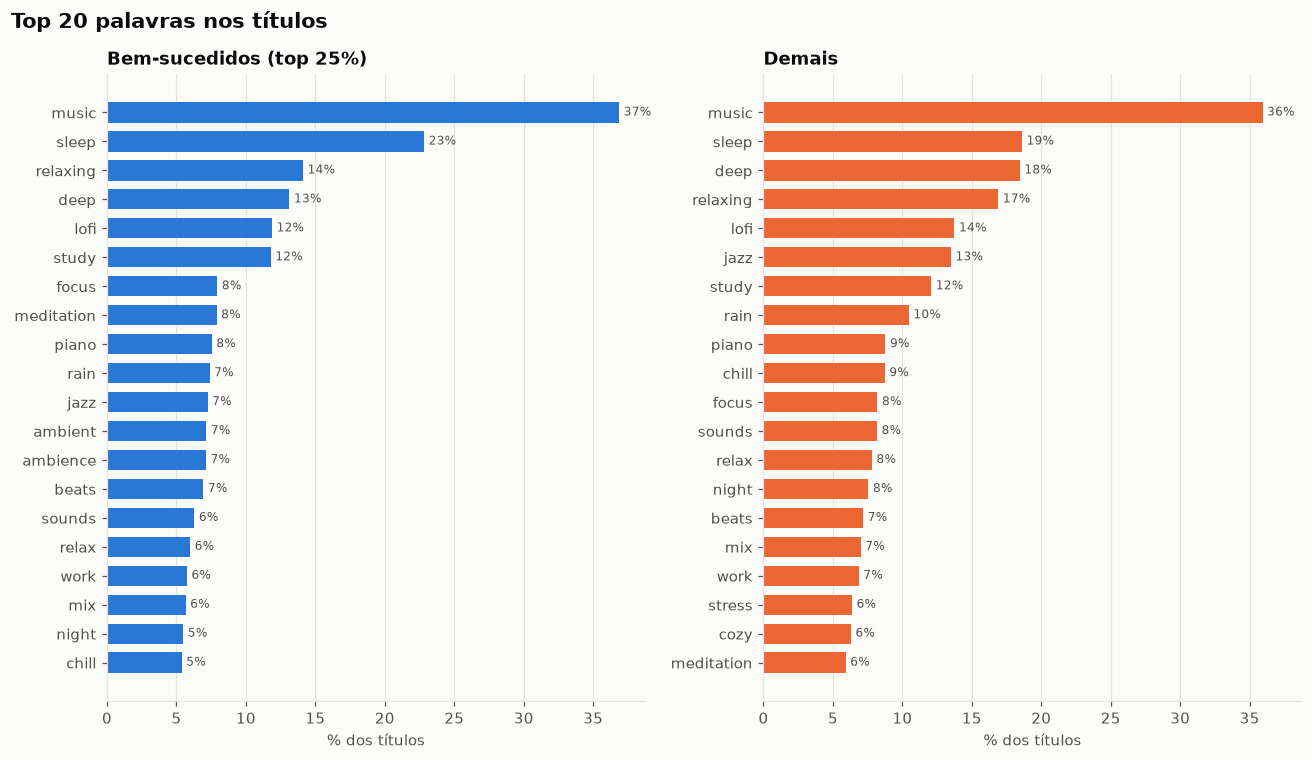

In [9]:
STOPWORDS = set("""
a an and the of to for in on with by from at or is it its my your our you me we i be are this that
de da do das dos e o os as em para com por um uma no na nos nas
la le les el y en del et des pour
ft feat official video vol part ep min hour hours hr hrs h
""".split())
WORD_PATTERN = re.compile(r"[a-zà-ÿ]{3,}")


def title_words(title):
    """Conjunto de palavras do título (sem repetição), em minúsculas e sem stopwords."""
    return {w for w in WORD_PATTERN.findall(str(title).lower()) if w not in STOPWORDS}


def top_words(titles, n=20):
    counts = Counter(w for t in titles for w in title_words(t))
    return (pd.Series(counts).sort_values(ascending=False).head(n) / len(titles) * 100)


top_success = top_words(videos.loc[videos["success"], "title"])
top_other = top_words(videos.loc[~videos["success"], "title"])

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharex=True)
for ax, (g, words) in zip(axes, [(True, top_success), (False, top_other)]):
    words = words.iloc[::-1]
    bars = ax.barh(words.index, words.values, color=GROUP_COLORS[g], height=0.7)
    ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=8, color=INK_MUTED)
    ax.set_title(GROUP_LABELS[g], loc="left")
    ax.set_xlabel("% dos títulos")
    ax.grid(axis="y", visible=False)
fig.suptitle("Top 20 palavras nos títulos", fontsize=14, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
save(fig, "palavras_titulos")

only_success = sorted(set(top_success.index) - set(top_other.index))
only_other = sorted(set(top_other.index) - set(top_success.index))
print("Só no top 20 dos bem-sucedidos:", only_success)
print("Só no top 20 dos demais:", only_other)

## 7. Números para as conclusões

In [10]:
def ratio(col):
    r = comparison.loc[FEATURES[col]]
    return r["mediana_sucesso"] / r["mediana_demais"]


facts = {
    "Inscritos (mediana)": comparison.loc["Inscritos", ["mediana_sucesso", "mediana_demais"]].tolist(),
    "Idade (anos)": comparison.loc["Idade do canal (anos)", ["mediana_sucesso", "mediana_demais"]].tolist(),
    "Uploads/semana": comparison.loc["Uploads por semana", ["mediana_sucesso", "mediana_demais"]].tolist(),
    "Duração média (min)": comparison.loc["Duração média (min)", ["mediana_sucesso", "mediana_demais"]].tolist(),
    "% lives/estreias": [channels.loc[channels.success, "live_pct"].mean(), channels.loc[~channels.success, "live_pct"].mean()],
    "% títulos com emoji (média)": [channels.loc[channels.success, "emoji_pct"].mean(), channels.loc[~channels.success, "emoji_pct"].mean()],
    "% títulos com '|' (média)": [channels.loc[channels.success, "pipe_pct"].mean(), channels.loc[~channels.success, "pipe_pct"].mean()],
    "Engajamento (mediana)": comparison.loc["Engajamento médio", ["mediana_sucesso", "mediana_demais"]].tolist(),
}
pd.DataFrame(facts, index=["Sucesso", "Demais"]).T.round(3)

,Sucesso,Demais
Inscritos (mediana),509500.000,57700.000
Idade (anos),7.737,5.487
Uploads/semana,0.526,2.108
Duração média (min),102.151,134.318
% lives/estreias,14.218,29.594
% títulos com emoji (média),26.638,36.400
% títulos com '|' (média),28.693,36.242
Engajamento (mediana),0.016,0.020


## 8. Conclusões

Números da coleta de 22/10/2026: 367 canais, sendo 92 bem-sucedidos (mediana ≥ ~15,6 mil views/vídeo).
Comparações de medianas por canal; p-valores do teste de permutação da seção 2.

1. **Postar menos, não mais.** Os bem-sucedidos publicam **0,53 vídeo/semana** contra **2,1** dos demais
   (4× menos; p < 0,001). É a feature de comportamento mais ligada à mediana de views (ρ = −0,36).
2. **Títulos mais curtos.** Mediana de **66 caracteres** contra **76** (p = 0,001).
3. **Menos "|" nos títulos.** O canal bem-sucedido típico usa "|" em **5,5%** dos títulos; os demais, em **23%**
   (p = 0,04). Títulos do tipo "palavra-chave | palavra-chave | palavra-chave" são mais comuns entre os menores.
4. **Pouca live/estreia.** Lives e estreias são em média **14%** dos vídeos dos bem-sucedidos contra **30%** dos demais
   (mediana 1% vs 5,7%; p = 0,06, no limite da significância).
5. **Evitam os vídeos ultralongos.** Vídeos com mais de 10 h são **10%** do catálogo dos bem-sucedidos contra **17%** dos demais;
   a faixa de 30–60 min é mais que o dobro (**9% vs 4%**). A duração média isolada, porém, não difere de forma significativa (p = 0,15).
6. **Tempo de casa conta.** Canais bem-sucedidos têm mediana de **7,7 anos** contra **5,5** (p = 0,009).
7. **Engajamento proporcional menor.** (likes + comentários)/views é **1,6%** nos bem-sucedidos e **2,0%** nos demais (p = 0,049):
   público maior e mais passivo, o esperado para música de fundo.

**O que não diferenciou os grupos:** emojis no título (p = 0,19), ano no título (p = 1,0) e nº total de vídeos (p = 0,68).
O vocabulário dos títulos é quase o mesmo nos dois grupos (18 das 20 palavras em comum).

**Limitações**
- É correlação, não causa. Ex.: canais grandes podem postar menos *porque* cada vídeo já rende muito.
- A busca por vídeos populares enviesa a amostra para canais de sucesso; o filtro de nicho por palavras-chave é imperfeito.
- "% de lives" inclui estreias (Premieres), que a API não separa de lives em `liveStreamingDetails`.
- Inscritos (ρ = 0,63) é mais consequência do que causa do sucesso, por isso não entra como "padrão".